# 10 · The Generator: plans, recorder, patch mode, profiling

`nxgen/pipeline.py` connects the modules. This notebook covers:

1. what the `Generator` does when it is created;
2. `sample_plan` and the plan, field by field;
3. `render`, step by step;
4. editing and replaying plans (debugging one image);
5. the `Recorder`: intermediate steps, saving, profiling;
6. patch mode: how it works, what is exact and what is approximate;
7. speed and memory.

In [1]:
from _setup import *
import json, copy, time
from nxgen import Generator, Recorder, load_config
from nxgen.core.io import save_json, load_json
ensure_template()

'/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/templates/case-1_hr0.2mm.nii.gz'

## 1. Creating a Generator

`Generator(templates, config, label_space=None, device)`:

1. loads the config (`load_config` if a path is given) and the tree;
2. loads every template, checks that voxels are isotropic and the same for all templates;
3. computes `factor = target_voxel_mm / hr_voxel_mm` (must be an integer);
4. builds the label space from the tree and the templates (or uses the one given, e.g. the
   frozen `label_space.json` of a dataset);
5. converts each template to int16 **indices**, pads it at the end of each axis to a multiple of
   `factor`, moves it to the device, and records its foreground box (for patch positions).

This is done once; then every image only reads the templates.

In [2]:
t0 = time.perf_counter()
gen = Generator([TEMPLATE], CONFIG, device=DEVICE)
print(f'created in {time.perf_counter() - t0:.1f} s')
t = gen.templates[0]
print('factor', gen.factor, '| HR voxel', gen.hr_voxel_mm, '| output voxel', gen.voxel_mm)
print('template HR shape (padded):', t['hr_shape'], '-> output shape', t['out_shape'])
print('foreground box on the output grid:', t['fg_lo'], '->', t['fg_hi'])
print('template on the GPU:', t['labels'].dtype, t['labels'].device, gb(t['labels'].numel() * 2))

created in 6.2 s
factor 2 | HR voxel 0.2 | output voxel 0.4
template HR shape (padded): [478, 878, 578] -> output shape [239, 439, 289]
foreground box on the output grid: [10, 11, 10] -> [229, 429, 279]
template on the GPU: torch.int16 cuda:3 0.49 GB


## 2. The plan

`sample_plan(seed, template=None, start=None)` draws everything random, module by module, each
from its own stream (notebook 01):

In [3]:
plan = gen.sample_plan(42)
def summary(v):
    """Shorten long lists (and round floats) for display."""
    if isinstance(v, list):
        return f'<list of {len(v)}>' if len(v) > 6 else [summary(x) for x in v]
    if isinstance(v, dict):
        return {k: summary(x) for k, x in v.items()}
    return round(v, 3) if isinstance(v, float) else v
for key, value in plan.items():
    print(f'{key:14s}', json.dumps(summary(value)))

version        1
seed           42
config_hash    "612a035fc7"
template       0
template_path  "/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/templates/case-1_hr0.2mm.nii.gz"
roi            {"start": [0, 0, 0], "size": [239, 439, 289]}
acquisition    {"mode": "aniso", "axis": 2, "spacing_mm": [0.4, 0.4, 0.746], "thickness_mm": [0.4, 0.4, 0.671], "alpha": [1.0, 1.0, 1.011], "sigma_vox": [0.0, 0.0, 1.243], "contrast": null}
morphology     {"ops": [{"grow": "background_l1", "shrink": "cerebral_gm_l1", "n_iter": 1, "grow_idx": [0], "shrink_idx": "<list of 72>"}, {"grow": "deep_gm_l1", "shrink": "cerebral_wm_l1", "n_iter": 2, "grow_idx": "<list of 120>", "shrink_idx": "<list of 8>"}]}
spatial        {"rotation_deg": [2.595, 2.091, -4.766], "zoom": [0.978, 1.043, 1.026], "shear": [0.0, 0.0, 0.0], "translation_mm": [0.0, 0.0, 0.0], "matrix": [[0.974, 0.087, 0.037], [-0.08, 1.038, -0.046], [-0.039, 0.044, 1.024]], "elastic_dmax_mm": 7.5, "elastic_ctrl_mm": [[[[

| key | content | notebook |
|---|---|---|
| `version`, `seed`, `config_hash` | identification (plan format, image seed, config) | 01 |
| `template`, `template_path` | which template | 03 |
| `roi` | `start` and `size` of the generated region on the output grid (full volume or patch) | this one |
| `acquisition` | step 0 | 04 |
| `morphology` | step 1 (`None` = not applied) | 05 |
| `spatial` | step 2 | 06 |
| `tree` | step 4 Gaussians, generation classes, noise seed | 08 |
| `bias`, `motion`, `noise` | step 5 (`None` = not applied) | 09 |

Steps without random parameters (partial volume, resolution, normalisation) take their settings
from the config at render time.

The plan is plain JSON: save it, load it, render it again.

In [4]:
path = os.path.join(OUTPUTS, 'plan_42.json')
save_json(plan, path)
print(f'{os.path.getsize(path) / 1e3:.0f} kB on disk')
a = gen.render(plan)
b = gen.render(load_json(path))
print('same segmentation:', torch.equal(a.seg, b.seg),
      '| max image difference:', float((a.image - b.image).abs().max()))

36 kB on disk
same segmentation: True | max image difference: 0.0


Images can differ by tiny floating-point amounts between runs on a GPU (non-deterministic
kernels). The segmentation is always identical.

## 3. `render`, step by step

```
crop          spatial.source_box: part of the template the region reads (+ morphology halo)
morphology    on the crop
spatial       deformed HR labels of the region
partial_volume -> seg (output grid) + top-k fractions
synthesis     image from the tree Gaussians
bias, motion
resolution    (+ noise on the low-res grid if noise.space = 'lowres')
noise         (on the output grid otherwise)
normalization
```

`render` returns a `Sample`: `image`, `seg`, `affine` (of the generated region), `plan`,
`normalization` (values used), `recorder`, and the shortcut `class_of`.

In [5]:
for field in ('image', 'seg'):
    v = getattr(a, field)
    print(f'{field:14s} {tuple(v.shape)} {v.dtype} {v.device}')
print(f'{"normalization":14s} {a.normalization}')
print(f'{"plan":14s} keys {list(a.plan)}')
print('affine of the output grid:\n', a.affine.round(3))
print('generation class of the first 10 labels:', a.class_of[:10])

image          (239, 439, 289) torch.float32 cuda:3
seg            (239, 439, 289) torch.int16 cuda:3
normalization  {'method': 'minmax', 'lo': -0.2651825249195099, 'hi': 0.820208728313446}
plan           keys ['version', 'seed', 'config_hash', 'template', 'template_path', 'roi', 'acquisition', 'morphology', 'spatial', 'tree', 'bias', 'motion', 'noise']
affine of the output grid:
 [[  0.4     0.      0.    -39.408]
 [  0.      0.4     0.    -84.624]
 [  0.      0.      0.4   -83.919]
 [  0.      0.      0.      1.   ]]
generation class of the first 10 labels: [0, 1, 2, 3, 3, 4, 5, 6, 6, 7]


## 4. Editing plans: debugging one image

Change one thing and keep everything else. A few useful edits:

| edit | effect |
|---|---|
| `plan['motion'] = None` (or `bias`, `morphology`, `spatial`) | remove that step |
| `plan['noise'] = None` | no noise |
| `plan['acquisition'] = None` | no resolution degradation (note: the tree visibility was drawn with the old resolution) |
| `plan['acquisition']['spacing_mm'] = [...]` | another acquisition (mode and slice profile are derived from the physical values) |
| `plan['tree']['sigma'] = [0] * K` | flat intensities (no texture) |
| `plan['roi'] = {...}` | another region |

Every augmentation section can be `None` (or missing); only `tree` is required.

In [ ]:
K = len(gen.labels)
variants = {
    'as drawn': plan,
    'no bias': dict(plan, bias=None),
    'no spatial': dict(plan, spatial=None, morphology=None),
    'no noise': dict(plan, noise=None),
    'flat tree': dict(plan, tree=dict(plan['tree'], sigma=[0.0] * K)),
}
show([gen.render(p).image for p in variants.values()], list(variants), axis=0, size=3)

## 5. The Recorder

`Recorder(steps=None | 'all' | [names], out_dir=None, profile=False)`:

* `steps`: which intermediate results to keep (moved to the CPU), in `rec.steps`;
* `out_dir`: also save them as `<nn>_<step>.nii.gz`, with the right affine (HR grid, output grid
  or low-res grid);
* `profile`: time and peak GPU memory of every step, in `rec.timings` (forces a GPU sync per step).

Without a recorder nothing is kept and nothing costs extra.

Step names that can be kept:

| name | grid | content |
|---|---|---|
| `template_crop` | HR | template crop (indices), before morphology |
| `morphology` | HR | the crop after morphology |
| `spatial` | HR | deformed labels of the region |
| `pv_seg` | output | segmentation (indices) |
| `pv_max` | output | largest partial-volume fraction per voxel |
| `pv_count` | output | number of labels per voxel |
| `synthesis` | output | image from the tree Gaussians |
| `bias`, `motion` | output | after each artefact |
| `lowres` | low-res | image on the acquisition grid (only if degraded) |
| `noise` | output | after the noise (only with `noise.space = 'highres'`) |
| `resolution` | output | after the resolution step (and low-res noise) |
| `image` | output | final normalised image |

In [7]:
out_dir = os.path.join(OUTPUTS, 'recorder_example')
rec = Recorder(steps='all', out_dir=out_dir, profile=True)
s = gen.render(plan, rec)
print('kept:', list(rec.steps))
print('files:', sorted(os.listdir(out_dir)))
print()
for name, tm in rec.timings.items():
    print(f'{name:15s} {tm["time_s"]:.3f} s   peak {tm["peak_gb"] or 0:.2f} GB')

kept: ['template_crop', 'morphology', 'spatial', 'pv_seg', 'pv_max', 'pv_count', 'synthesis', 'bias', 'motion', 'lowres', 'resolution', 'image']
files: ['01_template_crop.nii.gz', '02_morphology.nii.gz', '03_spatial.nii.gz', '04_pv_seg.nii.gz', '05_pv_max.nii.gz', '06_pv_count.nii.gz', '07_synthesis.nii.gz', '08_bias.nii.gz', '09_motion.nii.gz', '10_lowres.nii.gz', '11_resolution.nii.gz', '12_image.nii.gz']

crop            0.000 s   peak 0.88 GB
morphology      0.048 s   peak 7.19 GB
spatial         0.049 s   peak 3.08 GB
partial_volume  0.179 s   peak 3.38 GB
synthesis       0.024 s   peak 4.61 GB
bias            0.002 s   peak 1.31 GB
motion          0.000 s   peak 1.07 GB
resolution      0.006 s   peak 1.31 GB
normalization   0.001 s   peak 1.37 GB


The saved files open in any NIfTI viewer (e.g. Freeview, ITK-SNAP) over each other: the
HR-grid steps and the output-grid steps share world coordinates.

## 6. Patch mode

With `patch.size = [X, Y, Z]` (output voxels), each plan picks a patch: its centre is drawn
uniformly inside the foreground box of the template, then the patch is shifted to stay inside the
volume. Rendering then runs **backwards** to find what is needed, and **forwards** on crops only:

1. `spatial.source_box` → the template box the patch reads (exact, notebook 06);
2. crop + the morphology halo → morphology on the crop is exact (notebook 05);
3. deformation, partial volume, synthesis on the patch only;
4. bias and elastic fields evaluated at the patch's global positions (exact).

patch: {'start': [0, 169, 3], 'size': [160, 160, 160]}
template_crop  (380, 455, 388)
morphology     (380, 455, 388)
spatial        (320, 320, 320)
pv_seg         (160, 160, 160)
image          (160, 160, 160)


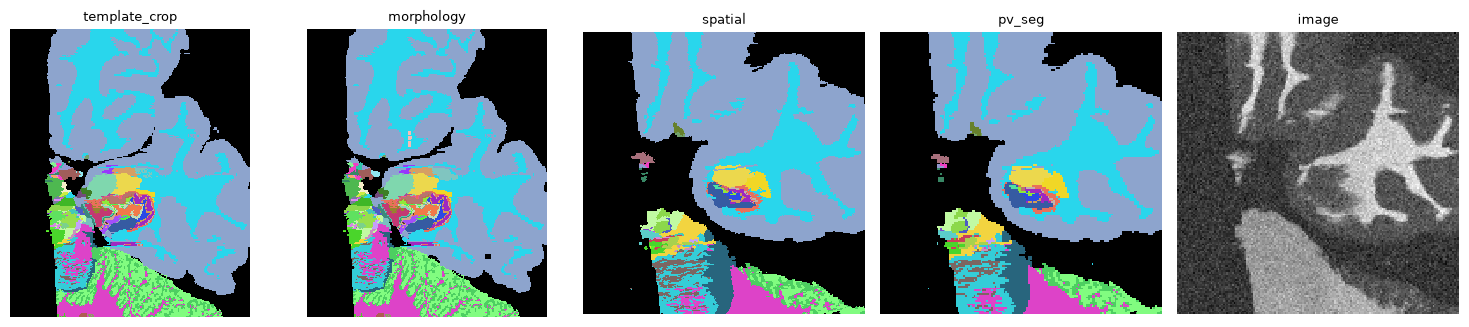

In [8]:
pgen = Generator([TEMPLATE], CONFIG_PATCH, device=DEVICE)
pplan = pgen.sample_plan(42)
print('patch:', pplan['roi'])
rec = Recorder(steps=['template_crop', 'morphology', 'spatial', 'pv_seg', 'image'])
ps = pgen.render(pplan, rec)
for n in rec.steps:
    print(f'{n:14s} {tuple(rec.steps[n].shape)}')
show([rec.steps[n] for n in rec.steps], list(rec.steps), size=3)

**What is exact and what is not.** A patch is identical to the same crop of a full-volume render
for the shape, the segmentation, the partial volumes, the tree means and the bias field. It
differs for:

* tree noise and acquisition noise: drawn per patch (same distribution, other values);
* motion: simulated on the patch (ghosts wrap inside the patch);
* resolution: the blur and resampling see the patch borders;
* normalisation: min/max of the patch.

Check: same plan, rendered as a full volume and as a patch, with noise, motion, degradation and
texture switched off:

In [ ]:
clean = dict(pplan, motion=None, noise=None, acquisition=None,
             tree=dict(pplan['tree'], sigma=[0.0] * K))
cfg_none = load_config(CONFIG, normalization={'method': 'none'})
cfg_none_patch = load_config(CONFIG_PATCH, normalization={'method': 'none'})
g_full = Generator([TEMPLATE], cfg_none, device=DEVICE)
g_patch = Generator([TEMPLATE], cfg_none_patch, device=DEVICE)
full = g_full.render(dict(clean, roi=dict(start=[0, 0, 0], size=t['out_shape'])))
part = g_patch.render(clean)
(x, y, z), (X, Y, Z) = clean['roi']['start'], clean['roi']['size']
print('segmentation identical:', torch.equal(part.seg, full.seg[x:x + X, y:y + Y, z:z + Z]))
print('image max difference  :', float((part.image - full.image[x:x + X, y:y + Y, z:z + Z]).abs().max()))
print('affine of the patch = full affine shifted:',
      np.allclose(part.affine[:3, 3], (full.affine @ [x, y, z, 1])[:3]))

## 7. Speed and memory

Per step, full volume vs patch (`profile=True`):

In [10]:
def profile(g, seeds=range(1, 4)):
    g(0)                                                  # warm-up
    acc = {}
    for sd in seeds:
        r = Recorder(profile=True)
        g(sd, recorder=r)
        for n, tm in r.timings.items():
            acc.setdefault(n, []).append(tm)
    return {n: (np.median([x['time_s'] for x in v]), max(x['peak_gb'] or 0 for x in v)) for n, v in acc.items()}

# free the other generators of this notebook first: their templates would count in the peaks
del g_full, g_patch, full, part, a, b, s, ps
import gc; gc.collect(); torch.cuda.empty_cache() if DEVICE.startswith('cuda') else None
pf, pp = profile(gen), profile(pgen)
print(f'{"step":15s} {"full s":>8s} {"full GB":>8s} {"patch s":>8s} {"patch GB":>9s}')
for n in pf:
    print(f'{n:15s} {pf[n][0]:8.3f} {pf[n][1]:8.2f} {pp[n][0]:8.3f} {pp[n][1]:9.2f}')
print(f'{"total":15s} {sum(v[0] for v in pf.values()):8.3f} {"":8s} {sum(v[0] for v in pp.values()):8.3f}')

step              full s  full GB  patch s  patch GB
crop               0.000     1.06    0.000      1.06
morphology         0.275     7.37    0.033      2.92
spatial            0.105     3.26    0.009      2.49
partial_volume     0.398     3.56    0.028      1.73
synthesis          0.061     4.80    0.004      1.57
bias               0.005     1.49    0.001      1.12
motion             0.000     1.25    0.000      1.09
resolution         0.002     1.62    0.000      1.14
normalization      0.003     1.50    0.000      1.12
total              0.851             0.076


Peak memory includes the templates held on the GPU by the two generators alive here (~0.5 GB
each). Times depend on how busy the GPU is (it may be shared). What keeps it fast:

* templates on the GPU as int16 indices, loaded once;
* no per-label loops in the online steps; the partial-volume histogram does not depend on the
  number of labels;
* parameters drawn on the CPU with numpy, small, no GPU syncs while drawing;
* patch mode: only what the patch needs.

For a full benchmark (more samples, worst case): `python tests/benchmark.py` (notebook 12).